Detect faces using Haar Cascade

Haar Cascade loaded successfully!


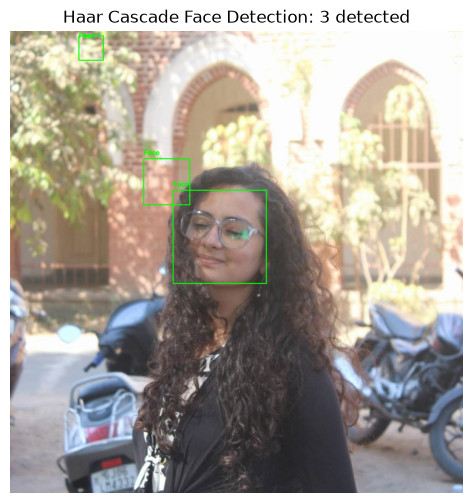

Number of faces detected: 3


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the original image
image_path = Path("../data/images/original.jpeg")
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path.resolve()}")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Load OpenCV's pre-trained frontal-face Haar Cascade

# Load the downloaded Haar Cascade XML file
cascade_path = (
    Path("../data/haarcascades")
    / "haarcascade_frontalface_default.xml"
)

if not cascade_path.exists():
    raise FileNotFoundError(
        f"Haar Cascade file not found: {cascade_path.resolve()}"
    )

face_cascade = cv2.CascadeClassifier(str(cascade_path))

if face_cascade.empty():
    raise RuntimeError(
        f"Could not load classifier from: {cascade_path.resolve()}"
    )

print("Haar Cascade loaded successfully!")


face_cascade = cv2.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise RuntimeError("Could not load the Haar Cascade classifier.")

# Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw bounding boxes
haar_result = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        haar_result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )
    cv2.putText(
        haar_result,
        "Face",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

# Display the result
plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(haar_result, cv2.COLOR_BGR2RGB))
plt.title(f"Haar Cascade Face Detection: {len(faces)} detected")
plt.axis("off")
plt.show()

print("Number of faces detected:", len(faces))


In [5]:

output_dir = Path("../outputs/detection")
output_dir.mkdir(parents=True, exist_ok=True)

success = cv2.imwrite(
    str(output_dir / "haar_face_detection.png"),
    haar_result
)

print("Saved successfully!" if success else "Save failed.")


Saved successfully!


Load YOLO and Detect objects


0: 640x640 2 persons, 1 car, 1 motorcycle, 511.3ms
Speed: 114.5ms preprocess, 511.3ms inference, 25.9ms postprocess per image at shape (1, 3, 640, 640)


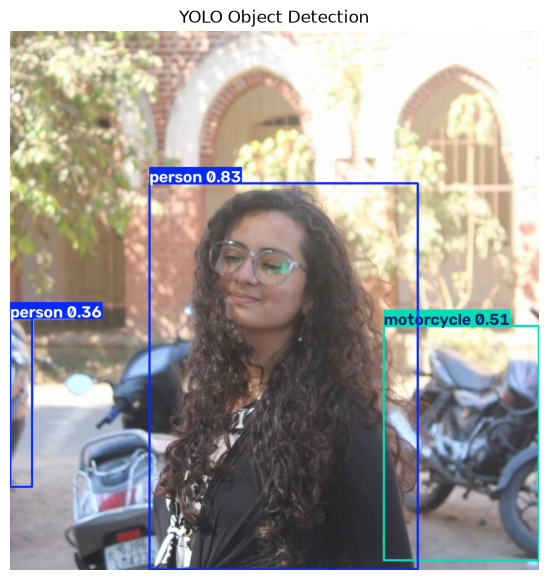

In [6]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Load a pretrained YOLO model
model = YOLO("yolov8n.pt")

# Run object detection on the original image
results = model(image)

# Draw the predicted bounding boxes and labels
yolo_result = results[0].plot()

# Display the result
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(yolo_result, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()


Print detected classes & confidence scores

In [7]:
# Print each detected object

result = results[0]

if result.boxes is None or len(result.boxes) == 0:
    print("No objects detected.")
else:
    for box in result.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        label = model.names[class_id]

        print(
            f"Class: {label} | "
            f"Confidence: {confidence:.2f} | "
            f"Bounding box: ({x1}, {y1}, {x2}, {y2})"
        )


Class: person | Confidence: 0.83 | Bounding box: (337, 368, 986, 1302)
Class: motorcycle | Confidence: 0.51 | Bounding box: (904, 713, 1279, 1280)
Class: person | Confidence: 0.36 | Bounding box: (0, 695, 53, 1102)
Class: car | Confidence: 0.35 | Bounding box: (0, 696, 54, 1101)


In [8]:

output_dir = Path("../outputs/detection")
output_dir.mkdir(parents=True, exist_ok=True)

success = cv2.imwrite(
    str(output_dir / "yolo_object_detection.png"),
    yolo_result
)

print("YOLO output saved!" if success else "Failed to save YOLO output.")


YOLO output saved!
